# Lab 3 A: Logistic Regression for Digits Classification

Imports, Data Loading & Binary Target Setup

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# 1. Load the Digits dataset (8x8 images -> 64 features)
digits = load_digits()
X = digits.data
y = digits.target

# 2. Convert labels: Digit 0 -> 1 (Positive), Digits 1-9 -> 0 (Negative)
y_binary = (y == 0).astype(int)

# 3. Split into 80% training and 20% testing data with fixed random_state
X_train, X_test, y_train, y_test = train_test_split(
    X, y_binary, test_size=0.20, random_state=42, stratify=y_binary
)

print(f"Feature matrix shape: {X.shape}")
print(f"Training samples: {X_train.shape[0]} | Testing samples: {X_test.shape[0]}")
print(f"Positive class (Digit 0) count in test set: {y_test.sum()} / {len(y_test)}")

Feature matrix shape: (1797, 64)
Training samples: 1437 | Testing samples: 360
Positive class (Digit 0) count in test set: 36 / 360


Task — Train Binary Logistic Regression & Predict

In [3]:
# Initialize and train the Binary Logistic Regression model
clf_digits = LogisticRegression(max_iter=1000, random_state=42)
clf_digits.fit(X_train, y_train)

# Generate predicted class labels for the test set
y_pred = clf_digits.predict(X_test)

Classification Metrics & Confusion Matrix

Accuracy : 1.0000
Precision: 1.0000
Recall   : 1.0000
F1 Score : 1.0000


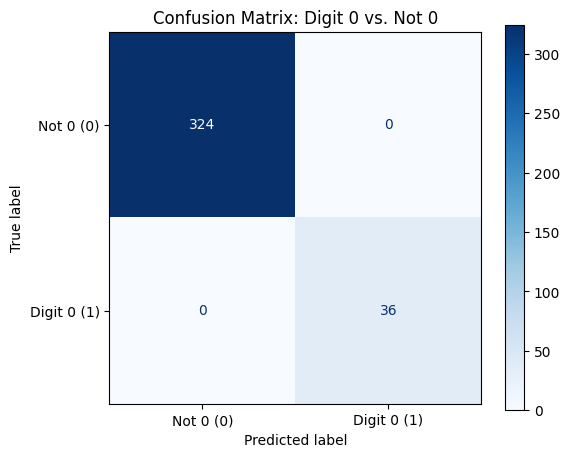

In [4]:
# Calculate evaluation metrics
acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)
rec = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print(f"Accuracy : {acc:.4f}")
print(f"Precision: {prec:.4f}")
print(f"Recall   : {rec:.4f}")
print(f"F1 Score : {f1:.4f}")

# Plot the Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Not 0 (0)", "Digit 0 (1)"])

fig, ax = plt.subplots(figsize=(6, 5))
disp.plot(cmap="Blues", ax=ax, values_format="d")
plt.title("Confusion Matrix: Digit 0 vs. Not 0")
plt.show()